In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl

In [4]:
!python -m pip install scikit-learn pandas matplotlib seaborn

In [5]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
    print(f"Precision: {precision_score(y_test, predictions, average='weighted'):.3f}")
    print(f"Recall:    {recall_score(y_test, predictions, average='weighted'):.3f}")
    print(f"F1-score:  {f1_score(y_test, predictions, average='weighted'):.3f}")
    print(classification_report(y_test, predictions, target_names=wine.target_names))


Logistic Regression
Accuracy:  0.972
Precision: 0.974
Recall:    0.972
F1-score:  0.972
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


Decision Tree
Accuracy:  0.944
Precision: 0.951
Recall:    0.944
F1-score:  0.945
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



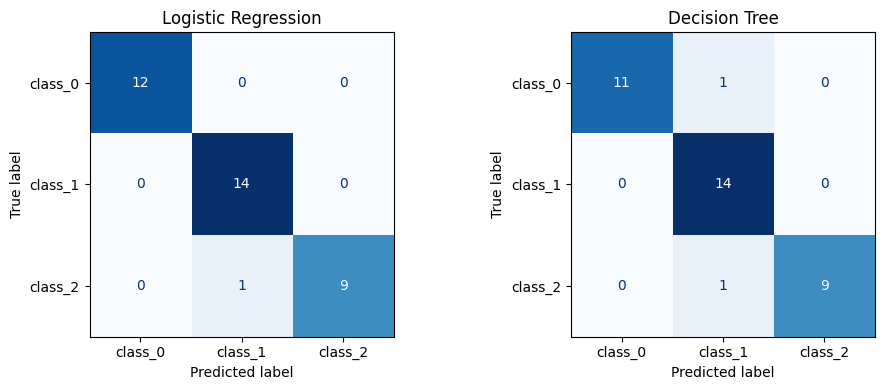

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=wine.target_names,
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [10]:
!python benchmark.py

python3: can't open file '/content/benchmark.py': [Errno 2] No such file or directory


In [11]:
"""Compare Logistic Regression and Decision Tree on scikit-learn's Wine data."""

from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


def main() -> None:
    wine = load_wine()
    X_train, X_test, y_train, y_test = train_test_split(
        wine.data,
        wine.target,
        test_size=0.2,
        random_state=42,
        stratify=wine.target,
    )

    # Scaling is fit on the training data inside each pipeline, preventing leakage.
    # Scaling is important for Logistic Regression; it does not affect tree splits.
    models = {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        ),
        "Decision Tree": make_pipeline(
            StandardScaler(), DecisionTreeClassifier(random_state=42)
        ),
    }

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        print(f"\n{name}")
        print("-" * len(name))
        print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
        print(
            "Precision (weighted): "
            f"{precision_score(y_test, predictions, average='weighted', zero_division=0):.3f}"
        )
        print(
            "Recall (weighted):    "
            f"{recall_score(y_test, predictions, average='weighted', zero_division=0):.3f}"
        )
        print(
            "F1-score (weighted):  "
            f"{f1_score(y_test, predictions, average='weighted', zero_division=0):.3f}"
        )
        print("Confusion matrix (rows = actual, columns = predicted):")
        print(confusion_matrix(y_test, predictions, labels=range(len(wine.target_names))))
        print(f"Class order: {', '.join(wine.target_names)}")


if __name__ == "__main__":
    main()



Logistic Regression
-------------------
Accuracy:  0.972
Precision (weighted): 0.974
Recall (weighted):    0.972
F1-score (weighted):  0.972
Confusion matrix (rows = actual, columns = predicted):
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
Class order: class_0, class_1, class_2

Decision Tree
-------------
Accuracy:  0.944
Precision (weighted): 0.951
Recall (weighted):    0.944
F1-score (weighted):  0.945
Confusion matrix (rows = actual, columns = predicted):
[[11  1  0]
 [ 0 14  0]
 [ 0  1  9]]
Class order: class_0, class_1, class_2


In [13]:
!python -m pip install scikit-learn
!python classification_benchmark.py

python3: can't open file '/content/classification_benchmark.py': [Errno 2] No such file or directory


In [14]:
!python benchmark.py

python3: can't open file '/content/benchmark.py': [Errno 2] No such file or directory


In [16]:
!python -m pip install scikit-learn pandas matplotlib seaborn

In [17]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame

print(df.head())
print(df["target"].value_counts())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

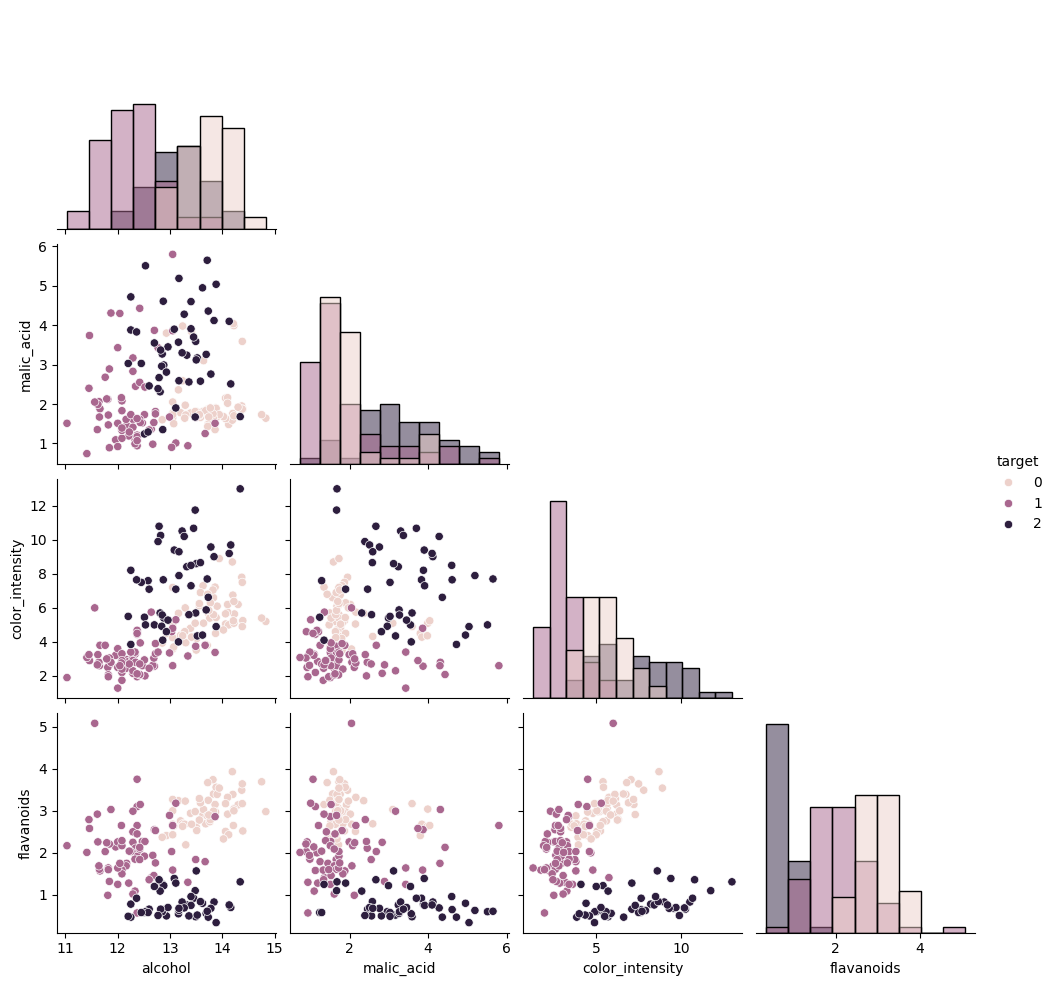

In [18]:
#exploratory pairplot
import seaborn as sns
import matplotlib.pyplot as plt

pairplot_features = ["alcohol", "malic_acid", "color_intensity", "flavanoids"]

sns.pairplot(
    df[pairplot_features + ["target"]],
    vars=pairplot_features,
    hue="target",
    diag_kind="hist",
    corner=True,
)
plt.show()

In [19]:
#Split the data and define scaled model pipelines
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
    "Decision Tree": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(random_state=42),
    ),
}

In [20]:
#Train the models and compare metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
    print(
        "Precision: "
        f"{precision_score(y_test, predictions, average='weighted'):.3f}"
    )
    print(
        "Recall:    "
        f"{recall_score(y_test, predictions, average='weighted'):.3f}"
    )
    print(
        "F1-score:  "
        f"{f1_score(y_test, predictions, average='weighted'):.3f}"
    )


Logistic Regression
Accuracy:  0.972
Precision: 0.974
Recall:    0.972
F1-score:  0.972

Decision Tree
Accuracy:  0.944
Precision: 0.951
Recall:    0.944
F1-score:  0.945


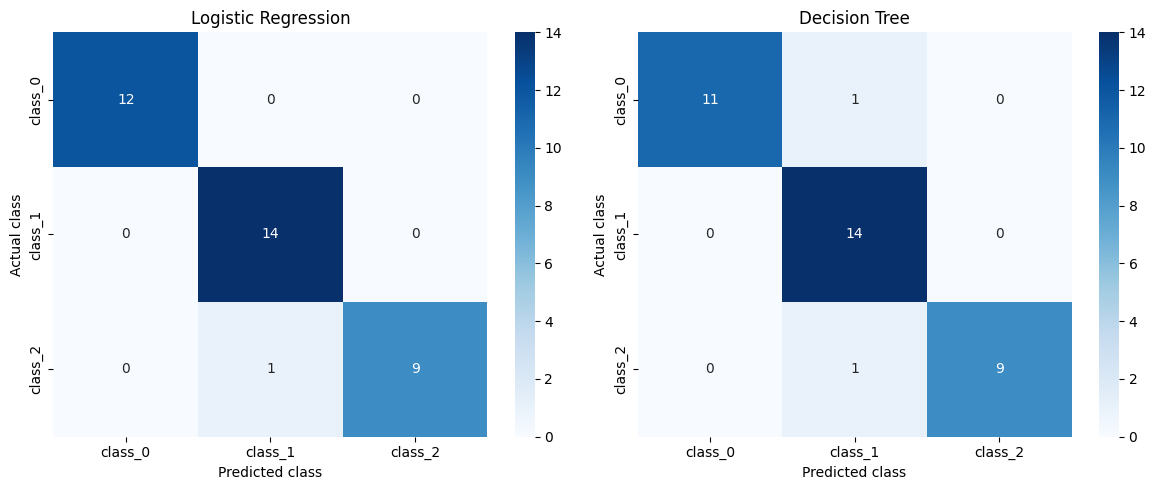

In [21]:
#Plot confusion-matrix heatmaps
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test, predictions)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=wine.target_names,
        yticklabels=wine.target_names,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

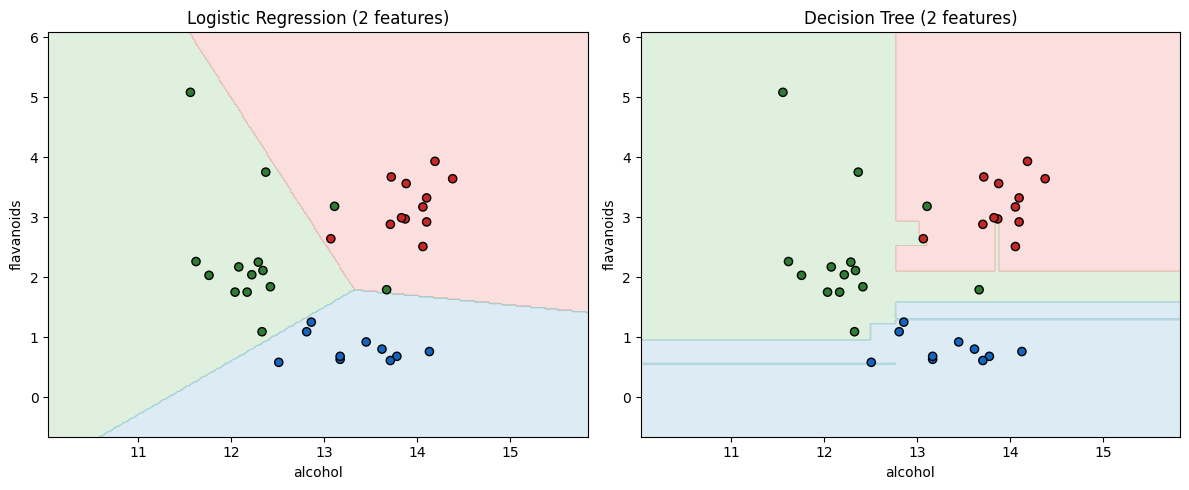

In [22]:
#Visualize a two-feature decision boundary
import numpy as np
from matplotlib.colors import ListedColormap

boundary_features = ["alcohol", "flavanoids"]
X_2d = df[boundary_features]
y_all = df["target"]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all,
)

# Plot one boundary per model.
boundary_models = {
    "Logistic Regression (2 features)": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
    "Decision Tree (2 features)": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(random_state=42),
    ),
}

colors = ListedColormap(["#f4a6a6", "#a8d5a2", "#9ecae1"])
points = ListedColormap(["#c62828", "#2e7d32", "#1565c0"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X_train_2d, y_train_2d)

    x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
    y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    grid = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=boundary_features,
    )
    regions = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, regions, cmap=colors, alpha=0.35)
    ax.scatter(
        X_test_2d.iloc[:, 0],
        X_test_2d.iloc[:, 1],
        c=y_test_2d,
        cmap=points,
        edgecolor="black",
        s=35,
    )
    ax.set_title(name)
    ax.set_xlabel(boundary_features[0])
    ax.set_ylabel(boundary_features[1])

plt.tight_layout()
plt.show()

In [23]:
!python classification_benchmark.py

python3: can't open file '/content/classification_benchmark.py': [Errno 2] No such file or directory


In [24]:
%%writefile classification_benchmark.py
# Paste the complete Python script here

Writing classification_benchmark.py


In [25]:
!python3 classification_benchmark.py

In [26]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'classification_benchmark.py', 'sample_data']


In [27]:
!python classification_benchmark.py